# V0.4 — historia previa y priorización de ofertas
Este notebook inspecciona la última prueba terminada sin reentrenar. Solo hay datos de 2024, ya explorados: los resultados son retrospectivos. La variante de adjudicaciones usa fechas proxy y queda fuera de la elección primaria. Consulta `README.md` y `CONCLUSIONES.md`.

In [1]:
from pathlib import Path
import json, sys, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
BASE=Path.cwd().resolve()
if not (BASE/'probar_historia.py').exists():
    BASE=BASE/'V0.4'
sys.path.insert(0,str(BASE))
import probar_historia as modelo
completas=sorted(p.parent for p in (BASE/'resultados').glob('*/estado_ejecucion.json'))
if not completas:
    raise FileNotFoundError('Ejecuta primero V0.4/probar_historia.py con el entorno de V0.2')
RUN=completas[-1]
informe=json.loads((RUN/'informe.json').read_text(encoding='utf-8'))
print('Ejecución:',RUN.name)
display(pd.DataFrame(informe['particiones']).T)
display(informe['cohorte'])

Ejecución: 20261104T164912115406Z


,filas,licitaciones,prevalencia,filas_ajuste
train,183490.0,9912.0,0.236258,80000.0
calibracion,17528.0,1422.0,0.248174,NaN
validacion,20610.0,1653.0,0.250315,NaN
test,169829.0,4930.0,0.095985,NaN


{'muestra_original': 691105,
 'filas_clave_repetida': 15692,
 'filas_clave_incompleta': 5040,
 'filas_envio_invalido': 24325,
 'filas_utilizadas': 391457,
 'nota': 'Causas solapadas; se excluyen claves ambiguas sin deduplicar ofertas distintas.'}

## Elección en validación
La base ya incluye proveedor y producto. Las tres variantes tienen la misma población y cortes. Se elige entre base y participaciones por precisión con recall mínimo del 30 %. La tasa histórica de adjudicaciones es solo una sensibilidad mientras no se verifiquen fechas efectivas.

In [2]:
validacion=pd.DataFrame(json.loads((RUN/'validacion.json').read_text(encoding='utf-8')))
display(validacion.drop(columns='matriz_confusion'))
display(informe['decision'])
display(pd.DataFrame(informe['test']).T.drop(columns='matriz_confusion'))
display(informe['bootstrap_por_licitacion'])

,variante,umbral,convergio,filas,prevalencia,precision,recall,average_precision,roc_auc,brier,log_loss,alertas,cobertura
0,base,0.377341,True,20610,0.250315,0.455313,0.303160,0.394678,0.670455,0.174896,0.527972,3435,0.166667
1,participaciones,0.391724,True,20610,0.250315,0.455414,0.304904,0.399720,0.683389,0.173662,0.524926,3454,0.167589
2,resultados_proxy,0.395846,True,20610,0.250315,0.455415,0.369258,0.423155,0.701954,0.170522,0.516436,4183,0.202960


{'variante': 'participaciones',
 'umbral': 0.3917237316083695,
 'antes_de_test': True,
 'criterio': 'Precisión con recall mínimo en validación; resultados_proxy excluida de selección primaria',
 'recall_minimo': 0.3,
 'min_alertas': 200}

,filas,prevalencia,precision,recall,average_precision,roc_auc,brier,log_loss,alertas,cobertura
base,169829,0.095985,0.140388,0.327833,0.13487,0.600646,0.138163,0.448559,38066,0.224143
participaciones,169829,0.095985,0.161509,0.323661,0.159799,0.652997,0.129917,0.427012,32667,0.192352
resultados_proxy,169829,0.095985,0.176492,0.391571,0.173306,0.661188,0.133378,0.432869,36166,0.212955


{'participaciones': {'precision_ic95': [0.09570789465828136,
   0.2538576492493967],
  'recall_ic95': [0.2932143139056189, 0.3515399494340003]},
 'base': {'precision_ic95': [0.08412801149169899, 0.21428190264094998],
  'recall_ic95': [0.2972831063098455, 0.35472182565526483]},
 'diferencia_precision_ganador_menos_base_ic95': [0.004803904982496937,
  0.05182603328498592]}

## Top 10 y top 20 por proveedor y mes
Se evalúan lotes con al menos k ofertas. La referencia aleatoria es la precisión esperada al seleccionar uniformemente dentro de cada lote. El agrupamiento retrospectivo no prueba disponibilidad simultánea ni define todavía la cartera real de una empresa.

,variante,k,lotes_elegibles,recomendaciones,seleccionadas,precision_topk,precision_aleatoria_esperada,lift_sobre_aleatorio,recall_lotes_elegibles,recall_macro_lotes_con_positivos
0,base,10,1827,18270,3089,0.169075,0.136024,1.242982,0.268375,0.508169
1,base,20,1270,25400,3331,0.131142,0.108080,1.213372,0.333534,0.551169
2,participaciones,10,1827,18270,3272,0.179091,0.136024,1.316620,0.284275,0.538967
3,participaciones,20,1270,25400,3536,0.139213,0.108080,1.288047,0.354060,0.593376
4,resultados_proxy,10,1827,18270,3355,0.183634,0.136024,1.350018,0.291486,0.550282
5,resultados_proxy,20,1270,25400,3618,0.142441,0.108080,1.317917,0.362271,0.602746


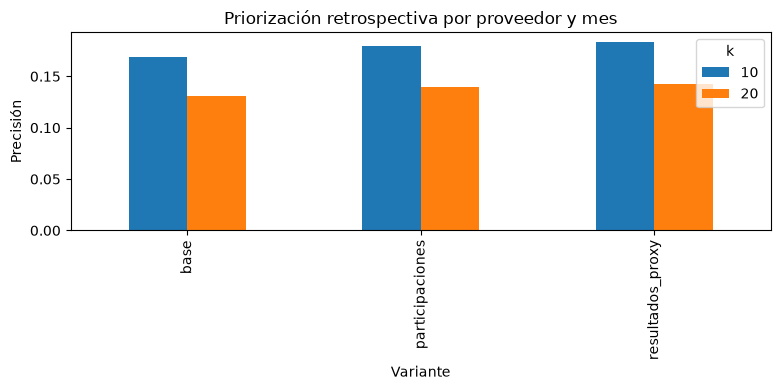

,mes,variante,filas,prevalencia,precision,recall,average_precision,roc_auc,brier,log_loss,alertas,cobertura
0,2024-10,base,6579,0.262806,0.468992,0.279931,0.433188,0.674592,0.177877,0.532757,1032,0.156863
1,2024-10,participaciones,6579,0.262806,0.480843,0.290341,0.459957,0.691869,0.175222,0.527007,1044,0.158687
2,2024-10,resultados_proxy,6579,0.262806,0.541026,0.366108,0.505799,0.726395,0.168155,0.508813,1170,0.177839
3,2024-11,base,55367,0.106670,0.175581,0.230105,0.159603,0.605563,0.123256,0.414302,7740,0.139794
4,2024-11,participaciones,55367,0.106670,0.222603,0.252794,0.188865,0.653629,0.118525,0.401077,6707,0.121137
5,2024-11,resultados_proxy,55367,0.106670,0.229882,0.303759,0.205357,0.662345,0.119561,0.401320,7804,0.140950
6,2024-12,base,95373,0.080337,0.137797,0.388932,0.136274,0.642364,0.131549,0.435758,21626,0.226752
7,2024-12,participaciones,95373,0.080337,0.159166,0.365570,0.165360,0.694670,0.120794,0.407700,17598,0.184518
8,2024-12,resultados_proxy,95373,0.080337,0.173547,0.451579,0.179477,0.701047,0.125562,0.416681,19937,0.209042
9,2025-01,base,12445,0.079711,0.067504,0.520161,0.101043,0.393399,0.233888,0.653888,7644,0.614223


In [3]:
ranking=pd.read_csv(RUN/'ranking_topk.csv')
display(ranking)
fig,ax=plt.subplots(figsize=(8,4))
ranking.pivot(index='variante',columns='k',values='precision_topk').plot.bar(ax=ax)
ax.set(ylabel='Precisión',xlabel='Variante',title='Priorización retrospectiva por proveedor y mes')
fig.tight_layout()
plt.show()
mensual=pd.DataFrame(json.loads((RUN/'diagnosticos_mensuales.json').read_text(encoding='utf-8')))
display(mensual.drop(columns='matriz_confusion'))

## Verificación del artefacto y su preparación
Se reconstruye la entrada del ejemplo con historia guardada bajo los cortes declarados. No se inventan ofertas ni se consulta el resultado futuro para crear sus predictores.

In [4]:
artefacto=joblib.load(RUN/'modelo_candidato.joblib')
raw=pd.read_parquet(RUN/'muestra_cruda.parquet')
d,partes,_,_=modelo.cohort(raw,'2026-11-04')
historia=pd.read_parquet(RUN/'historia_consultada.parquet')
cols=[c for c in historia if c.endswith(('_participaciones_log','_resultados_log','_adjudicadas_log','_tasa_suavizada'))]
historia=historia[cols]
idx=partes['test'][:12]
salida=modelo.predict(artefacto,d.iloc[idx],historia.iloc[idx])
pred=pd.read_parquet(RUN/'predicciones_test.parquet')
np.testing.assert_allclose(salida.probabilidad,pred[artefacto['variante']].iloc[:len(salida)])
display(salida)
display(Markdown(chr(10).join(['### Limitaciones','']+['- '+x for x in informe['limitaciones']])))
print('Promovido:',artefacto['promovido'])

,probabilidad,prediccion
221628,0.130518,0
221629,0.231270,0
221630,0.428861,1
221631,0.277924,0
221632,0.508737,1
221633,0.232844,0
221634,0.502766,1
221635,0.273557,0
221636,0.420737,1
221637,0.233082,0


### Limitaciones

- Solo 2024; todo el periodo ya fue observado. No hay confirmación independiente.
- La historia de participaciones supone que envíos previos eran observables; para competidores puede ser falso. Debe existir registro propio o acceso efectivo.
- Las tasas de adjudicación usan fecha final más demora, no fecha efectiva verificada; variante solo experimental.
- El modelo clasifica ofertas de distintos proveedores; una aplicación para una empresa requiere evaluar su cartera específica.
- Top-k agrupa retrospectivamente por proveedor y mes de envío; no demuestra disponibilidad simultánea de oportunidades.
- Se excluyen claves repetidas y envíos inválidos. La población difiere de V0.3 y no se comparan directamente sus cifras.
- Se congela la historia en el inicio de calibración/validación/test; no se actualiza con etiquetas del mismo conjunto.
- Historia desde enero: no hay antecedentes de años anteriores y el entrenamiento tiene arranque sin historia.
- La selección por madurez de resultado introduce sesgo hacia procesos rápidos; faltan snapshots y horizontes comparables.

Promovido: False
